In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [2]:
df = pd.read_csv('/Users/mateoflores/Documents/Tec/OptimizacionEstocastica/data/ratings.csv')
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df.head(5)



,rating,id_company,date
0,CCC,BMV_001,2019-01-01
1,BB,BMV_001,2019-02-01
2,BB,BMV_001,2019-03-01
3,B,BMV_001,2019-04-01
4,BBB,BMV_001,2019-05-01


In [3]:
rating = df['rating'].value_counts(normalize = True).reset_index()
rating

,rating,proportion
0,BB,0.357634
1,BBB,0.283356
2,B,0.215956
3,A,0.090784
4,CCC,0.026135
5,AA,0.016506
6,AAA,0.005502
7,CC,0.002751
8,D,0.001376


In [4]:
rating = df['id_company'].value_counts(normalize = True).reset_index()
rating

,id_company,proportion
0,BMV_007,0.185695
1,BMV_005,0.141678
2,BMV_003,0.140303
3,BMV_001,0.126547
4,BMV_002,0.126547
5,BMV_008,0.125172
6,BMV_004,0.110041
7,BMV_006,0.044017


In [5]:
def genZeroMatriz():
    P = np.array([
    #.  AAA, AA, A, BBB, BB, B, CCC, CC, C, DDD, DD, D
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # AAA
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # AA
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # A
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # BBB
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # BB
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # B
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # CCC
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # C
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # C
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # DD
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], # DD
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.] # D
        ])
    return P

mapa = {
    'AAA': 0,
    'AA': 1,
    'A': 2,
    'BBB': 3,
    'BB': 4,
    'B': 5,
    'CCC': 6,
    'CC': 7,
    'C': 8,
    'DDD': 9,
    'DD': 10,
    'D': 11
    }

def getIndex(rating):
    return mapa[rating]

In [6]:
def calcDistForCompany(company):
    company_df = df[df['id_company'] == company]
    company_df.sort_values(by='date', inplace=True)
    P = genZeroMatriz()
    for i in range(len(company_df)-1):
        current_rating = company_df.iloc[i]['rating']
        next_rating = company_df.iloc[i+1]['rating']
        P[getIndex(current_rating)][getIndex(next_rating)] += 1
    return P

In [7]:
def normalize_row(row):
    sum_row = np.sum(row)
    for i in range(len(row)):
        row[i] = row[i] / sum_row if sum_row > 0 else row[i]
    return row

def scale_matrix(P):
    for i in range(P.shape[0]):
        P[i] = normalize_row(P[i])
    return P

In [8]:
companies = df['id_company'].dropna().unique()
dict_P = {}

for i, company in enumerate(companies):
    P = scale_matrix(calcDistForCompany(company))
    dict_P[company] = P

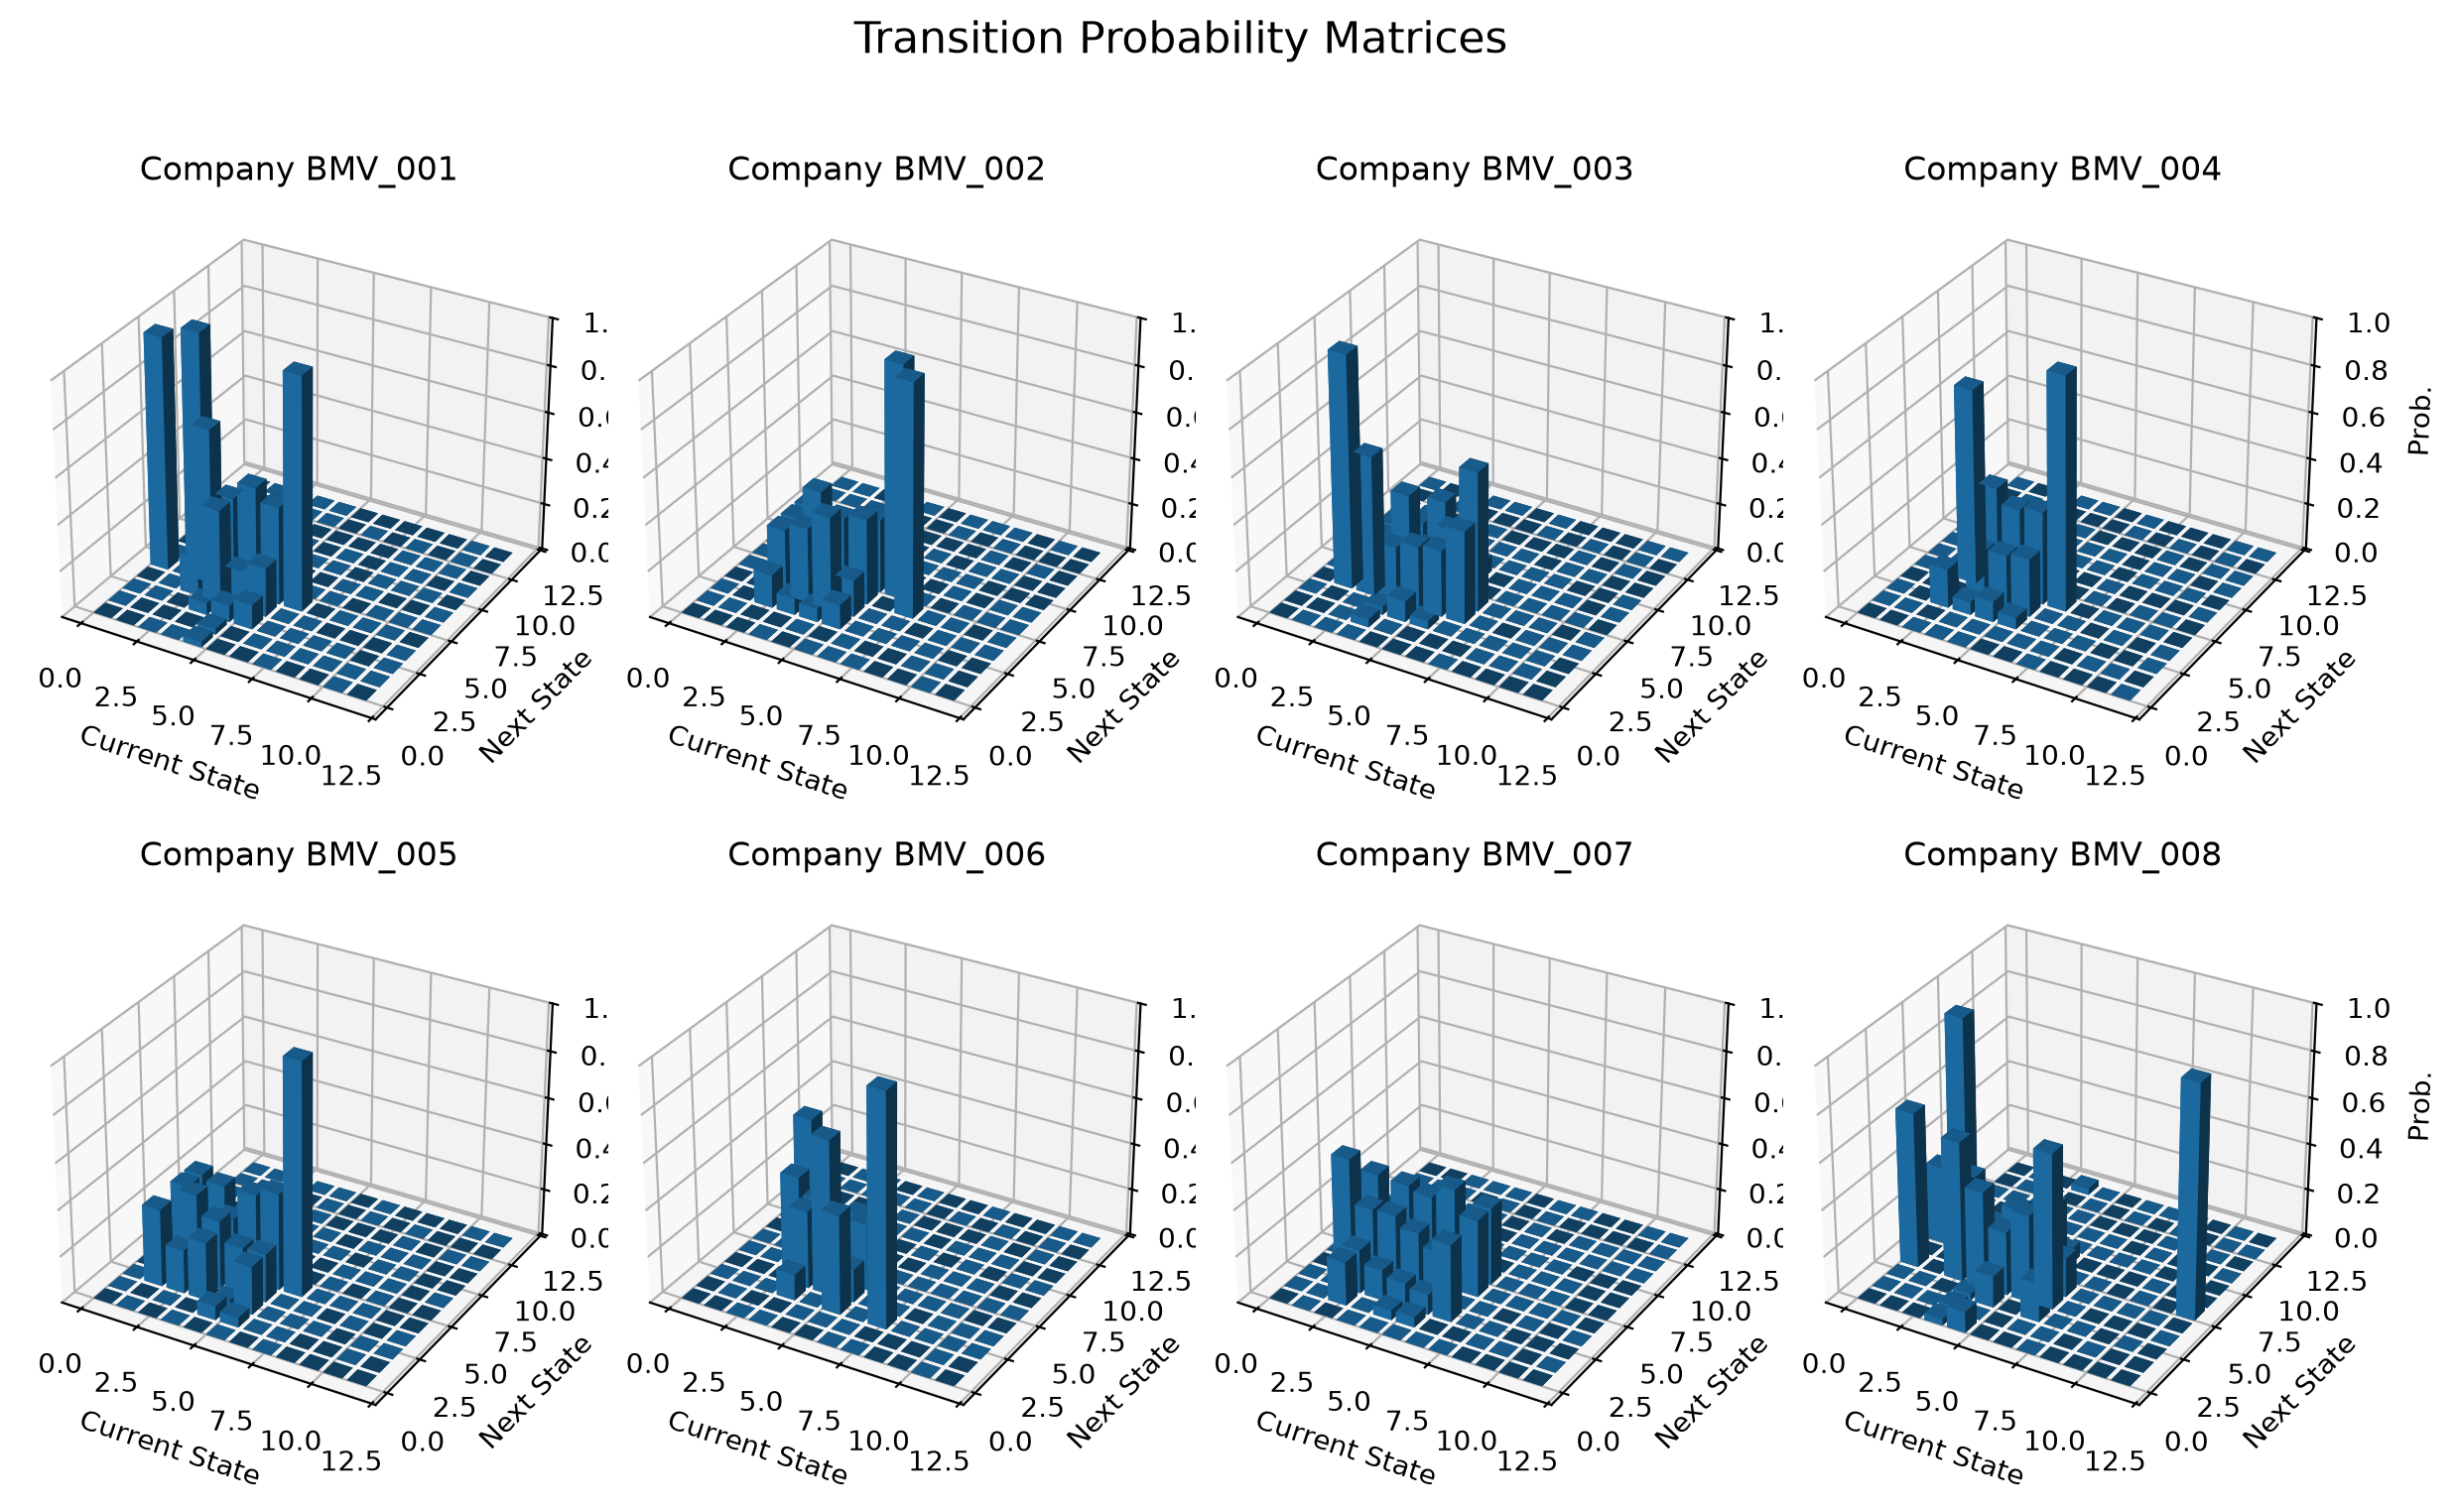

In [9]:
n = len(companies)
rows = int(np.ceil(n / 4))

fig, axes = plt.subplots(rows, 4, figsize=(12,8),
                         subplot_kw={'projection': '3d'})
axes = np.atleast_2d(axes)

for i, company in enumerate(companies):
    P = dict_P[company]

    ax = axes[i // 4, i % 4]

    x = np.arange(P.shape[0])
    y = np.arange(P.shape[1])
    X, Y = np.meshgrid(x, y)
    Z = P[X, Y]

    ax.bar3d(X.ravel(), Y.ravel(), np.zeros_like(Z).ravel(),
             0.8, 0.8, Z.ravel(), shade=True)

    ax.set_xlabel('Current State')
    ax.set_ylabel('Next State')
    ax.set_zlabel('Prob.')
    ax.set_title(f'Company {company}')
    ax.set_zlim(0, 1)

# Apaga ejes sobrantes
for j in range(n, rows * 3):
    axes[j // 3, j % 3].axis('off')

fig.suptitle('Transition Probability Matrices', fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
def getLast(company):
    company_df = df[df['id_company'] == company]
    company_df.sort_values(by='date', inplace=True)
    last_rating = company_df.iloc[-1]['rating']
    date = company_df.iloc[-1]['date'] 
    print(f"Last rating on {date.strftime('%Y-%m-%d')} : {last_rating}")
    return last_rating, date

def getNext(company, current_rating):
    P = dict_P[company]
    current_index = getIndex(current_rating)
    next_probabilities = P[current_index]
    next_index = np.argmax(next_probabilities)
    next_rating = list(mapa.keys())[list(mapa.values()).index(next_index)]
    return next_rating

def getNextDate(last_date):
    # Assuming last_date is a pandas Timestamp object
    next_date = last_date + pd.DateOffset(months=1)
    return next_date

In [11]:
def main(target_month):
    for i, company in enumerate(companies):
        print(f"--COMPANY {company}--")
        P = dict_P[company]
        last_rating, last_date = getLast(company)
        while last_date < target_month:
            next_rating = getNext(company, last_rating)
            last_date = getNextDate(last_date)
            last_rating = next_rating

            print(f"Next rating on {last_date.strftime('%Y-%m-%d')} : {next_rating} ")
        print("")

target_month = pd.Timestamp('2026-09-01')  # Example target month
main(target_month)

--COMPANY BMV_001--
Last rating on 2026-08-01 : BB
Next rating on 2026-09-01 : BB 

--COMPANY BMV_002--
Last rating on 2026-08-01 : B
Next rating on 2026-09-01 : BB 

--COMPANY BMV_003--
Last rating on 2026-06-01 : BBB
Next rating on 2026-07-01 : BB 
Next rating on 2026-08-01 : B 
Next rating on 2026-09-01 : BB 

--COMPANY BMV_004--
Last rating on 2026-08-01 : BB
Next rating on 2026-09-01 : BB 

--COMPANY BMV_005--
Last rating on 2026-07-01 : BBB
Next rating on 2026-08-01 : BBB 
Next rating on 2026-09-01 : BBB 

--COMPANY BMV_006--
Last rating on 2026-08-01 : BBB
Next rating on 2026-09-01 : BBB 

--COMPANY BMV_007--
Last rating on 2026-08-01 : BB
Next rating on 2026-09-01 : BB 

--COMPANY BMV_008--
Last rating on 2026-08-01 : BBB
Next rating on 2026-09-01 : BBB 

